# Лекция 10. Неравенства: условия ККТ

**Курс:** Вычислительная оптимизация · **Часть IV. Неравенства** · Лекция 10 из 16 · 3 декабря 2026

**Материалы:** [конспект-ноутбук с кодом демонстраций](lecture10.ipynb) · [демо-ноутбук](demo10.ipynb) · [разбор упражнений](exercises10.ipynb)

В конспекте-ноутбуке текст идёт подряд, а три демо собраны в конце: (a) к §2, (b) к §3, (c) к §4. Семинар — у доски, задачи в §8.

---

> **Код в этом ноутбуке.** Текст лекции идёт подряд, без кода. Три демо из [`demo10.ipynb`](demo10.ipynb) собраны в конце, в разделе «Демо»: (a) к §2 — условия ККТ в задаче «парк», (b) к §3 — портфель руками и IPOPT, (c) к §4 — точки при $\mu h=\tau$. Подробности — только в `demo10.ipynb`. Нужен CasADi: `uv run --group casadi jupyter lab`, в Colab он ставится сам.

## Введение

В лекциях 8–9 ограничения были равенствами. На практике чаще встречаются неравенства: доля актива не меньше нуля, груз не ниже пола, скорость не больше предельной. Сегодня — система условий для таких задач и главная трудность её решения. Две задачи: «парк» и «портфель».

### Задача 1. Дом и парк

Круглый парк радиуса 1 с центром в начале координат. Дом стоит в точке $a$. Где ближайшая к дому точка парка?

$$
\min_{x\in\mathbb R^2}\ f(x)=\tfrac12\lVert x-a\rVert^2\qquad\text{при}\qquad h(x)=1-x_1^2-x_2^2\ge0 .
$$

Здесь $x=(x_1,x_2)\in\mathbb R^2$ — точка плоскости. Функция $f$ — половина квадрата расстояния до дома. Неравенство $h\ge0$ значит, что точка лежит в парке или на его границе.

<img src="img/00_park.png" width="560" alt="круг радиуса 1 — парк; дом внутри в точке (0.5, 0.3) и дом снаружи в точке (2, 1)">

*Парк и два дома: внутри, $a=(0.5,\ 0.3)$, и снаружи, $a=(2,\ 1)$.*

**Две системы.** Ответ здесь виден глазами. Если дом в парке, ближайшая точка — сам дом. Ограничение тогда ни при чём, и условие такое же, как без ограничений: $\nabla f=x-a=0$.

Если дом снаружи, ближайшая точка лежит на границе парка. Ограничение работает как равенство $h=0$, и годится условие лекции 8: $\nabla f=\mu\nabla h$. Множитель неравенства обозначим $\mu$, как в лекции 3. Градиенты: $\nabla f=(x_1-a_1,\ x_2-a_2)$ и $\nabla h=(-2x_1,\ -2x_2)$. Покомпонентно:

$$
\begin{aligned}
x_1-a_1&=-2\mu x_1,\\
x_2-a_2&=-2\mu x_2,\\
1-x_1^2-x_2^2&=0 .
\end{aligned}
$$

Первые два уравнения — градиенты параллельны, третье — точка на границе парка.

**3 уравнения на 3 неизвестных: $x_1$, $x_2$ и $\mu$.**

Для дома внутри система другая: $x-a=0$, два уравнения на два неизвестных. Какую систему решать, мы знаем только потому, что видим картинку. Солвер картинки не видит — ему нужна одна система на оба случая.

### Задача 2. Портфель без коротких продаж

Инвестор вкладывает капитал в четыре актива — например, в четыре фонда. Он хочет получать в среднем $\rho=12\,\%$ годовых и рисковать как можно меньше.

**Данные.** Это учебные данные лекции 3, не рыночные.

| Актив | Средняя доходность $r_i$ | Волатильность $\sigma_i$ |
|---|---:|---:|
| 1 | 4 % | 5 % |
| 2 | 8 % | 12 % |
| 3 | 11 % | 18 % |
| 4 | 15 % | 30 % |

Доходность актива за год заранее неизвестна — это случайная величина. Число $r_i$ — её среднее. Волатильность $\sigma_i$ — её среднеквадратичное отклонение: насколько доходность колеблется вокруг среднего. Чем выше средняя доходность актива, тем сильнее он колеблется.

**Переменные.** $x=(x_1,\dots,x_4)\in\mathbb R^4$ — доли капитала в четырёх активах. Например, $x=(0.25,\ 0.25,\ 0.25,\ 0.25)$ — капитал разделён поровну.

**Задача:**

$$
\min_{x\in\mathbb R^4}\ \tfrac12x^\top\Sigma x\qquad\text{при}\qquad \mathbf 1^\top x=1,\quad r^\top x=\rho,\quad x\ge0 .
$$

Что значит каждая часть:

- $\mathbf 1^\top x=x_1+x_2+x_3+x_4=1$ — весь капитал вложен;
- $r^\top x=0.04x_1+0.08x_2+0.11x_3+0.15x_4=0.12$ — средняя доходность портфеля равна 12 %; это среднее доходностей активов с весами $x_i$;
- $x\ge0$, то есть $x_i\ge0$ для каждого актива, — запрет коротких продаж (что это — ниже);
- $\tfrac12x^\top\Sigma x$ — риск портфеля.

**Риск и матрица $\Sigma$.** Доходность портфеля — это сумма $x_1R_1+x_2R_2+x_3R_3+x_4R_4$, где $R_i$ — доходность актива $i$. Её дисперсия равна $x^\top\Sigma x$. Здесь $\Sigma$ — ковариационная матрица доходностей размера $4\times4$:

$$
\Sigma_{ij}=\sigma_i\,\sigma_j\,c_{ij} .
$$

Число $c_{ij}$ — корреляция доходностей активов $i$ и $j$ из лекции 3: от $0$ у пары 1–4 до $0.5$ у пары 2–3. На диагонали $c_{ii}=1$, и там стоят квадраты волатильностей: $\Sigma_{11}=0.05^2=0.0025$. Вне диагонали, например, $\Sigma_{34}=0.18\cdot0.30\cdot0.4=0.0216$. Целиком:

$$
\Sigma=\begin{pmatrix}
0.0025&0.0012&0.0009&0\\
0.0012&0.0144&0.0108&0.0108\\
0.0009&0.0108&0.0324&0.0216\\
0&0.0108&0.0216&0.09
\end{pmatrix}.
$$

Множитель $\tfrac12$ стоит для удобства: градиент риска тогда равен $\Sigma x$.

**Что значит отрицательная доля.** Без условия $x\ge0$ это задача семинара лекции 8. Её ответ:

<img src="img/00_portfolio.png" width="620" alt="столбцы долей четырёх активов: -0.20, 0.50, 0.43, 0.27; столбец актива 1 красный, ниже нуля">

*Ответ лекции 8, без неравенств $x\ge0$: доля актива 1 равна $-0.20$.*

Доля $x_1=-0.20$ — это короткая продажа (*short sale*):

1. взять у брокера в долг актив 1 на 20 % капитала и сразу его продать;
2. на вырученные деньги вместе со своим капиталом купить активы 2–4 — на $0.50+0.43+0.27=1.20$ капитала.

Сумма долей по-прежнему $-0.20+1.20=1$. Средняя доходность $-0.2\cdot4+0.5\cdot8+0.43\cdot11+0.27\cdot15\approx12\,\%$.

Почему так выгодно: актив 1 приносит всего 4 %, меньше цели. Колеблется он мало, поэтому его заём почти не добавляет риска. А вырученные деньги идут в доходные активы. Но для короткой продажи нужен заём, и многим инвесторам она недоступна или запрещена. Отсюда условие $x\ge0$.

**Система.** Без неравенств это система лекции 8: градиент риска $\Sigma x$ — комбинация градиентов двух равенств.

$$
\begin{aligned}
\Sigma x-\lambda_1\mathbf 1-\lambda_\rho r&=0 &&\text{(4 уравнения)},\\
\mathbf 1^\top x&=1,\\
r^\top x&=\rho .
\end{aligned}
$$

**6 уравнений на 6 неизвестных: $x_1,\dots,x_4$, $\lambda_1$ и $\lambda_\rho$.**

Её решение нарушает $x_1\ge0$. В ответе с запретом каждая доля либо положительна, либо равна нулю. Получается $2^4=16$ вариантов, и у каждого своя система. Какой вариант верный?

**Зачем это вам.** IPOPT, OSQP и `scipy.optimize.minimize` с границами решают ту систему, которую мы сегодня выпишем. Понимать её — значит понимать, какие числа возвращает солвер и что они значат.

**Главная тема лекции — условия ККТ:** одна система для задач с неравенствами.

Три вопроса:

1. Какая одна система описывает и дом внутри парка, и дом снаружи?
2. Как найти, какие ограничения работают как равенства, — в портфеле из 16 вариантов?
3. Почему метод Ньютона–Лагранжа из лекции 9 не решает эту систему напрямую?

План:

- §1 — что уже знаем: условие лекции 8 и «стенка» лекции 3;
- §2 — условия ККТ: задача «парк», общий вид, теорема;
- §3 — активное множество: портфель руками;
- §4 — почему Ньютону трудно и что делают солверы;
- §5 — что это даёт численно; семинар у доски — §8.

## 1. Что уже знаем

**Главная мысль.** Для равенств есть система лекции 8. Для одного неравенства, на границе которого стоит решение, есть условие лекции 3 со знаком множителя.

**Равенства (лекция 8).** Задача $\min f(x)$ при $g(x)=0$, где $x\in\mathbb R^n$ и $g$ — это $m$ функций. Условие решения:

$$
\nabla f(x)=J(x)^\top\lambda,\qquad g(x)=0 .
$$

Здесь $J$ — якобиан $g$, матрица $m\times n$, а $\lambda\in\mathbb R^m$ — множители. Всего $n+m$ уравнений на $n+m$ неизвестных. Функция Лагранжа $L=f-\lambda^\top g$.

**Одна стенка (лекция 3).** Вспомним завод с контрактом. Себестоимость выпуска $x$ единиц — $f(x)=(x-2)^2$, а контракт требует $h(x)=x-3\ge0$. Безусловный минимум $x=2$ нарушает контракт, поэтому решение у стенки: $x^\ast=3$. В нём $f'(3)=2=\mu\,h'(3)$, то есть $\mu=2$.

Знак здесь важен: $\mu\ge0$. Стенка может только толкать внутрь допустимой области, тянуть наружу она не умеет.

| Случай | Что знаем | Чего не знаем |
|---|---|---|
| Равенства | систему лекции 8 и метод Ньютона–Лагранжа | — |
| Одно неравенство | $\nabla f=\mu\nabla h$ и $\mu\ge0$ у стенки | как узнать, что решение у стенки |
| Много неравенств | — | какие из них работают |

## 2. Условия ККТ

**Главная мысль.** Оба случая задачи «парк» описывает одна система. К условию лекции 8 добавляются $h\ge0$, $\mu\ge0$ и условие $\mu h=0$.

### 2.1. Задача «парк»: два случая — одна система

Задача:

$$
\min_{x\in\mathbb R^2}\ \tfrac12\lVert x-a\rVert^2\qquad\text{при}\qquad h(x)=1-x_1^2-x_2^2\ge0 .
$$

Запишем условие стенки сразу для обоих случаев:

$$
\nabla f(x)=\mu\nabla h(x),\qquad\text{то есть}\qquad x-a=-2\mu x .
$$

**Дом внутри**, $a=(0.5,\ 0.3)$. Ответ $x^\ast=a$, левая часть равна нулю, значит $\mu=0$. Ограничение выполнено строго: $h(x^\ast)=1-0.25-0.09=0.66>0$.

**Дом снаружи**, $a=(2,\ 1)$. Из $x-a=-2\mu x$ получаем $x=a/(1+2\mu)$ — точку на отрезке от центра парка к дому. Подставим её в $h=0$: $\lVert a\rVert=1+2\mu$. Отсюда $\mu=(\lVert a\rVert-1)/2=(\sqrt5-1)/2=0.618$ и $x^\ast=a/\lVert a\rVert=(0.894,\ 0.447)$.

<img src="img/01_park_cases.png" width="900" alt="две панели: слева дом внутри парка, ответ совпадает с домом; справа дом снаружи, ответ на границе, стрелка минус градиента f смотрит к дому, стрелка градиента h — к центру парка">

*Слева дом внутри: ограничение не работает, $\mu=0$. Справа дом снаружи: точка на границе, $h=0$. Стрелки $-\nabla f$ к дому и $\nabla h$ внутрь парка лежат на одной прямой.*

**Что общего.** В обоих случаях одно из двух чисел $\mu$ и $h$ равно нулю: внутри $\mu=0$, на границе $h=0$. Значит, всегда $\mu h=0$.

**Зачем знак $\mu\ge0$.** У системы для границы есть второе решение: $x=-a/\lVert a\rVert=(-0.894,\ -0.447)$ и $\mu=-(\sqrt5+1)/2=-1.618$. Это самая дальняя от дома точка границы. Из неё шаг внутрь парка приближает к дому, так что это не минимум. Отрицательный $\mu$ это и показывает.

Соберём всё вместе. Точка $x^\ast$ — решение, если для неё найдётся $\mu$ с четырьмя условиями:

$$
\begin{aligned}
x-a+2\mu x&=0 &&\text{стационарность},\\
1-x_1^2-x_2^2&\ge0 &&\text{допустимость},\\
\mu&\ge0 &&\text{знак множителя},\\
\mu\,\big(1-x_1^2-x_2^2\big)&=0 &&\text{дополняющая нежёсткость}.
\end{aligned}
$$

Последнее условие по-английски называют *complementarity*. Оно значит: из двух чисел $\mu$ и $h$ хотя бы одно равно нулю. Проверьте на домах: внутри $\mu=0$, снаружи $h=0$.

**3 уравнения на 3 неизвестных** — два уравнения стационарности и $\mu h=0$ — плюс два неравенства.

### 2.2. Общий вид

Задача с равенствами и неравенствами:

$$
\min_{x\in\mathbb R^n}\ f(x)\qquad\text{при}\qquad g(x)=0,\quad h(x)\ge0 .
$$

*Размеры:* $g$ — это $m$ равенств, $h=(h_1,\dots,h_p)$ — это $p$ неравенств. Множители: $\lambda\in\mathbb R^m$ у равенств и $\mu\in\mathbb R^p$ у неравенств. Функция Лагранжа $L=f-\lambda^\top g-\mu^\top h$, знак как в лекции 8.

**Условия ККТ** (Каруша–Куна–Таккера, *KKT conditions*):

$$
\begin{aligned}
\nabla f(x)-J_g(x)^\top\lambda-J_h(x)^\top\mu&=0,\\
g(x)&=0,\\
h(x)&\ge0,\\
\mu&\ge0,\\
\mu_i\,h_i(x)&=0,\qquad i=1,\dots,p .
\end{aligned}
$$

*Размеры:* $J_g$ — якобиан $g$, матрица $m\times n$; $J_h$ — якобиан $h$, матрица $p\times n$. Уравнений $n+m+p$, неизвестных столько же: $x$, $\lambda$ и $\mu$. К ним добавляются $2p$ неравенств.

| Условие | Смысл |
|---|---|
| $\nabla_xL=0$ | сила $-\nabla f$ уравновешена реакциями ограничений |
| $g=0$, $h\ge0$ | точка допустима |
| $\mu\ge0$ | стенка толкает только внутрь |
| $\mu_ih_i=0$ | у неработающего ограничения множитель равен нулю |

**Активное множество** (*active set*) — номера неравенств, которые в точке выполнены как равенства:

$$
\mathcal A(x)=\{\,i:\ h_i(x)=0\,\}.
$$

В задаче «парк» для дома снаружи $\mathcal A=\{1\}$, для дома внутри $\mathcal A$ пусто. Пусть активное множество известно. Тогда неравенства из него — равенства, а остальные можно выбросить. Остаётся задача лекции 8.

### 2.3. Теорема ККТ

**Зачем теорема.** Солверы ищут точку, где выполнены условия ККТ. Это имеет смысл, только если в решении такие множители всегда есть. Теорема говорит, когда это так.

Нужно условие LICQ из лекции 8, но только для активных ограничений. Градиенты всех $g_j$ и всех активных $h_i$ в точке $x^\ast$ должны быть линейно независимы. В задаче «парк» для дома снаружи градиент один: $\nabla h(x^\ast)=(-1.789,\ -0.894)$. Один вектор линейно независим, если он ненулевой, — LICQ выполнено.

**Теорема (условия ККТ).** Пусть $x^\ast$ — локальный минимум, функции $f$, $g$, $h$ гладкие и в $x^\ast$ выполнено LICQ. Тогда найдутся $\lambda^\ast\in\mathbb R^m$ и $\mu^\ast\in\mathbb R^p$, с которыми в $x^\ast$ выполнены все условия ККТ.

**Доказательство.**

**Шаг 1. Неактивные ограничения не мешают.** Если $h_i(x^\ast)>0$, то по непрерывности $h_i>0$ и рядом с $x^\ast$. На малые сдвиги такое ограничение не влияет; положим $\mu_i=0$. Активные ограничения $h_i=0$ станут равенствами. Точка $x^\ast$ — минимум и для задачи с равенствами $g=0$ и $h_i=0$, $i\in\mathcal A$: её допустимые точки рядом с $x^\ast$ допустимы и для исходной задачи. По теореме лекции 8 при LICQ найдутся множители, для которых

$$
\nabla f(x^\ast)=J_g(x^\ast)^\top\lambda+\sum_{i\in\mathcal A}\mu_i\nabla h_i(x^\ast).
$$

Условие $\mu_ih_i=0$ тоже выполнено: у активных ограничений $h_i=0$, у неактивных $\mu_i=0$.

**Шаг 2. Знак множителя.** Пусть у активного ограничения $h_k$ получилось $\mu_k<0$. По LICQ строки $\nabla g_j^\top$ и $\nabla h_i^\top$, $i\in\mathcal A$, линейно независимы. Поэтому найдётся направление $d$, для которого $\nabla h_k^\top d=1$, а все остальные эти строки дают $0$. Сдвиг вдоль $d$ уводит от стенки $k$ внутрь и не нарушает остальных ограничений. Строго — вдоль кривой с касательной $d$, как в лекции 8. Производная $f$ вдоль $d$:

$$
\nabla f(x^\ast)^\top d=\mu_k\,\nabla h_k(x^\ast)^\top d=\mu_k<0 .
$$

Значит, $f$ уменьшается, и $x^\ast$ не минимум. Противоречие — поэтому $\mu_k\ge0$. В задаче «парк» это видно в самой дальней точке: там $\mu=-1.618<0$, и шаг внутрь приближает к дому.

**Что из неё следует.**

- При LICQ в каждом локальном минимуме выполнены условия ККТ. Поэтому солверы ищут решение системы ККТ.
- Как и в лекции 8, условие только необходимое: ему могут удовлетворять и не минимумы. Для выпуклых задач оно и достаточное. Выпуклость здесь значит: $f$ выпукла, $g$ линейны, все $h_i$ вогнуты. Задача «парк» и портфель выпуклые, поэтому точка ККТ в них — глобальный минимум.
- Если LICQ нарушено, множителей в минимуме может не быть. Пример — в упражнении 10.4.

## 3. Активное множество

**Главная мысль.** Если угадать активное множество, условия ККТ становятся системой лекции 8. Догадку проверяют по двум знакам: $h_i\ge0$ у неактивных ограничений и $\mu_i\ge0$ у активных.

### 3.1. Схема «угадай и проверь»

1. Выбрать активное множество $\mathcal A$ — номера неравенств, которые считаем равенствами.
2. Решить систему лекции 8 с ограничениями $g=0$ и $h_i=0$, $i\in\mathcal A$. Остальные неравенства выбросить, их $\mu_i=0$. Неизвестных $n+m+\lvert\mathcal A\rvert$.
3. Проверить допустимость: $h_i(x)\ge0$ для всех $i\notin\mathcal A$. Если какое-то нарушено — добавить его в $\mathcal A$ и вернуться к шагу 2.
4. Проверить знаки: $\mu_i\ge0$ для всех $i\in\mathcal A$. Если какой-то $\mu_i<0$ — убрать $i$ из $\mathcal A$ и вернуться к шагу 2.
5. Обе проверки прошли — найдена точка ККТ. В выпуклой задаче, как «парк» и «портфель», это глобальный минимум.

Внутри схемы та же система, что в методе Ньютона–Лагранжа. Новое — внешний перебор активных множеств. Это учебная схема, а не готовый метод: гарантии, что догадки не пойдут по кругу, у неё нет. В невыпуклой задаче точка ККТ может и не быть минимумом. Настоящий метод активного множества — тема лекции 11.

### 3.2. Портфель руками

Задача:

$$
\min_{x\in\mathbb R^4}\ \tfrac12x^\top\Sigma x\qquad\text{при}\qquad \mathbf 1^\top x=1,\quad r^\top x=0.12,\quad x\ge0 .
$$

Неравенств четыре: $h_i(x)=x_i\ge0$. Их градиенты — базисные векторы: $\nabla h_i=e_i$, где у $e_i$ единица на месте $i$, остальные нули.

**Догадка 1, $\mathcal A=\varnothing$.** Все неравенства выброшены — это задача лекции 8. Система $6\times6$:

$$
\begin{pmatrix}\Sigma&-\mathbf 1&-r\\ \mathbf 1^\top&0&0\\ r^\top&0&0\end{pmatrix}
\begin{pmatrix}x\\ \lambda_1\\ \lambda_\rho\end{pmatrix}
=\begin{pmatrix}0\\ 1\\ 0.12\end{pmatrix}.
$$

Решение: $x=(-0.2015,\ 0.4981,\ 0.4324,\ 0.2710)$. Проверка допустимости не прошла: $x_1<0$. Добавляем первое ограничение: $\mathcal A=\{1\}$.

**Догадка 2, $\mathcal A=\{1\}$.** Добавляются уравнение $x_1=0$ и неизвестное $\mu_1$. Стационарность теперь такая:

$$
\Sigma x-\lambda_1\mathbf 1-\lambda_\rho r-\mu_1e_1=0 .
$$

Система $7\times7$:

$$
\begin{pmatrix}\Sigma&-\mathbf 1&-r&-e_1\\ \mathbf 1^\top&0&0&0\\ r^\top&0&0&0\\ e_1^\top&0&0&0\end{pmatrix}
\begin{pmatrix}x\\ \lambda_1\\ \lambda_\rho\\ \mu_1\end{pmatrix}
=\begin{pmatrix}0\\ 1\\ 0.12\\ 0\end{pmatrix}.
$$

Решение: $x=(0,\ 0.1414,\ 0.5026,\ 0.3560)$ и $\mu_1=0.0082$. Остальные доли положительны, и $\mu_1\ge0$. Обе проверки прошли — это точка ККТ. Задача выпуклая, поэтому это ответ. Из 16 вариантов понадобилось две догадки.

<img src="img/02_portfolio_weights.png" width="900" alt="доли четырёх активов в зависимости от требуемой доходности от 6 до 14.5 процента; пунктир без запрета, сплошные линии с запретом; доля актива 1 без запрета уходит ниже нуля после 10.64 процента, с запретом остаётся нулём">

*Доли от требуемой доходности. Пунктир — без запрета: доля актива 1 отрицательна при $\rho>10.64\,\%$. Сплошные линии — с $x\ge0$: доля актива 1 остаётся нулём, а при $\rho>12.69\,\%$ обнуляется и доля актива 2.*

**Цена запрета.** Запрет виден в риске: среднеквадратичное отклонение доходности портфеля $\sqrt{x^\top\Sigma x}$ растёт с $16.9\,\%$ до $17.4\,\%$.

**Множитель — цена.** Как в лекции 8, множитель показывает, как меняется минимальный риск при сдвиге ограничения. Цена доходности $\lambda_\rho$ без запрета равна $0.351$, с запретом — $0.473$. С запретом каждый процент доходности обходится дороже по риску. Множитель $\mu_1=0.0082$ — это выигрыш в риске, если разрешить немного занять актив 1.

**Вопрос залу.** При какой доходности активное множество станет $\{1,\ 2\}$?

<details>
<summary>Ответ</summary>

При $\rho>12.69\,\%$: там на картинке обнуляется доля актива 2. При $\rho=13\,\%$ и $14\,\%$ схема приходит к $\mathcal A=\{1,\ 2\}$ — упражнение 10.3.

</details>

**Что это значит для методов.** Перебор 16 вариантов терпим. Но у портфеля из 1000 активов вариантов $2^{1000}$. Хороший метод проходит лишь несколько активных множеств, как здесь — два. Об этом лекция 11.

## 4. Почему Ньютону трудно

**Главная мысль.** Метод Ньютона решает систему равенств и не учитывает условий $\mu\ge0$ и $h\ge0$. А около вершины «уголка» $\mu h=0$ матрица его шага вырождается. Выходов два: угадать активное множество или перейти к гладкой кривой $\mu h=\tau$.

Метод Ньютона–Лагранжа лекции 9 решает систему уравнений $F(z)=0$: на шаге он заменяет каждое уравнение его касательной. В условиях ККТ есть неравенства $\mu\ge0$ и $h\ge0$, а их метод Ньютона не знает: его шаг может увести в $\mu<0$ или $h<0$.

Нарисуем допустимые пары $(h,\mu)$ одного ограничения. Это две полуоси: $\mu=0$ при $h\ge0$ и $h=0$ при $\mu\ge0$. Вместе они образуют уголок с вершиной в точке $(0,0)$.

<img src="img/03_complementarity.png" width="900" alt="слева на плоскости h, mu — уголок из двух полуосей и две гиперболы mu h = 0.1 и mu h = 0.01; дом внутри лежит на горизонтальной полуоси, дом снаружи — на вертикальной; справа парк и точки внутри него при tau = 1, 0.1, 0.01, приближающиеся к ответу">

*Слева: уголок $\mu h=0$, $\mu\ge0$, $h\ge0$ и гиперболы $\mu h=\tau$. Два дома задачи «парк» лежат на разных сторонах уголка. Справа: в задаче «парк» точки с $\mu h=\tau$ лежат внутри парка и приближаются к $x^\ast$ при уменьшении $\tau$.*

На какой стороне уголка ответ, заранее неизвестно. В задаче «парк» дом внутри даёт одну сторону, дом снаружи — другую. Выбрать сторону для каждого ограничения — это и значит выбрать активное множество.

Само уравнение $\mu h=0$ гладкое: его производные по $h$ и по $\mu$ — это $(\mu,\ h)$. Но в вершине $(0,0)$ обе равны нулю. Строка матрицы шага для этого уравнения нулевая, и матрица вырождена. Рядом с вершиной она почти вырождена.

**Выход 1: угадать сторону.** На стороне $\mu_i=0$ ограничение выбрасываем, на стороне $h_i=0$ оно становится равенством. Остаётся система лекций 8–9. Так устроен метод активного множества — лекция 11.

**Выход 2: сгладить уголок.** Заменим $\mu h=0$ на $\mu h=\tau$ с малым $\tau>0$. У этой гиперболы две ветви, и берём ветвь в положительной четверти: $h>0$, $\mu>0$. Само равенство $\mu h=\tau$ этого не гарантирует — оба числа могут быть и отрицательными. Поэтому метод внутренней точки укорачивает шаг Ньютона, чтобы $\mu$ и $h$ оставались положительными (лекция 12). На этой ветви вершины нет, и система из одних уравнений решается методом Ньютона. Потом $\tau$ уменьшают, и точка приближается к условию $\mu h=0$.

В задаче «парк» с домом $(2,\ 1)$ при $\tau=0.1$ точка лежит на расстоянии $0.07$ от ответа. При $\tau=0.01$ — на расстоянии $0.008$. Все эти точки внутри парка: $h>0$. Так работает метод внутренней точки — лекция 12. Так устроен и IPOPT. Как считаются эти точки — в демо (c).

## 5. Что это даёт численно

**Главная мысль.** Солверы возвращают множители неравенств. Знак у каждого солвера свой — сверяйте его по задаче с известным ответом.

- **IPOPT через CasADi.** Границы $x\ge0$ задаются аргументами `lbx` и `ubx`, множители границ — в поле `lam_x`. Для портфеля при $\rho=12\,\%$ IPOPT делает 9 итераций. Он возвращает `lam_x` $=(-0.0082,\ 0,\ 0,\ 0)$ и `lam_g` $=(0.0265,\ -0.4731)$. В `lam_g` — наши $\lambda$ со знаком минус, как в лекции 8 (демо (b)). `lam_x` отрицателен у активной нижней границы и положителен у верхней, его модуль — наш $\mu$ (упражнение 10.2).
- **SciPy.** `minimize(method="SLSQP")` с аргументом `bounds` решает подзадачи методом активного множества. `linprog` возвращает множители неравенств в `res.ineqlin.marginals` (лекция 3).

**ДЗ 5** (Ньютон–Лагранж и обобщённый Гаусс–Ньютон) сдаётся 05.12.

## 6. Итоги лекции

1. Условия ККТ — это стационарность, допустимость, $\mu\ge0$ и $\mu_ih_i=0$. Из двух чисел $\mu_i$ и $h_i$ хотя бы одно равно нулю (§2).
2. При LICQ на активных ограничениях условия ККТ выполнены в каждом локальном минимуме. В выпуклой задаче точка ККТ — глобальный минимум (§2.3).
3. Если знать активное множество, остаётся система лекции 8. Догадку проверяют знаками $h_i\ge0$ и $\mu_i\ge0$ (§3).
4. Метод Ньютона не учитывает $\mu\ge0$ и $h\ge0$, а у вершины уголка $\mu h=0$ его матрица вырождается. Выходы — угадать активное множество (лекция 11) или ветвь $\mu h=\tau$ в положительной четверти (лекция 12) (§4).

**Ответы на задачи введения.**

- **Задача 1.** Дом $(0.5,\ 0.3)$ внутри парка — ответ сам дом, $\mu=0$. Дом $(2,\ 1)$ снаружи — ответ $(0.894,\ 0.447)$, $\mu=0.618$. Обе точки удовлетворяют одной системе ККТ.
- **Задача 2.** При $\rho=12\,\%$ активна одна граница, $x_1=0$. Доли $(0,\ 0.141,\ 0.503,\ 0.356)$, $\mu_1=0.0082$. Хватило двух догадок.

## 7. Что дальше

**Лекция 11** — линейное и квадратичное программирование: метод активного множества. **Лекция 12** — методы внутренней точки: гипербола $\mu h=\tau$ вместо уголка.

**ДЗ 5** — срок 05.12.

**Литература к лекции.**

- Diehl, *Lecture Notes on Numerical Optimization*, часть IV — условия оптимальности для задач с неравенствами.
- Nocedal & Wright: §12.1–12.3 — примеры, условия регулярности и теорема 12.1 (условия ККТ); §16.5 — метод активного множества для выпуклой квадратичной задачи, к лекции 11.
- Boyd & Vandenberghe: §5.5.3 — условия ККТ и их достаточность для выпуклых задач.

## 8. Семинар у доски

Около 30 минут, три задачи руками. Ответы спрятаны — сначала решите сами.

| Мин | Задача |
|---|---|
| 8 | **С1. Одна стенка, два случая** |
| 10 | **С2. Проекция на четверть плоскости** |
| 12 | **С3. Треугольник: неверная догадка** |

**С1.** Выпишите условия ККТ и решите задачу $\min_{x\in\mathbb R}\ (x+1)^2$ (а) при $x\ge0$; (б) при $x\ge-2$.

<details>
<summary>Ответ</summary>

Стационарность: $2(x+1)=\mu$, ограничение $h=x-c\ge0$.

- (а) Безусловный минимум $x=-1$ нарушает $x\ge0$. Ограничение активно: $x^\ast=0$, $\mu=2(0+1)=2\ge0$.
- (б) Безусловный минимум $x=-1$ допустим: $h=-1+2=1>0$. Ограничение неактивно, $\mu=0$.

</details>

**С2.** Найдите ближайшую к точке $a=(-1,\ 2)$ точку четверти плоскости:

$$
\min_{x\in\mathbb R^2}\ \tfrac12\lVert x-a\rVert^2\qquad\text{при}\qquad x_1\ge0,\quad x_2\ge0 .
$$

<details>
<summary>Ответ</summary>

Стационарность: $x-a=\mu_1e_1+\mu_2e_2$, то есть $x_1+1=\mu_1$ и $x_2-2=\mu_2$. Догадка $\mathcal A=\{1\}$: $x_1=0$, $\mu_2=0$. Тогда $x_2=2$ и $\mu_1=1\ge0$. Проверка: $x_2=2\ge0$. Ответ $x^\ast=(0,\ 2)$, $\mu=(1,\ 0)$.

</details>

**С3.** Ближайшая к точке $a=(0.2,\ -1)$ точка треугольника:

$$
\min_{x\in\mathbb R^2}\ \tfrac12\lVert x-a\rVert^2\qquad\text{при}\qquad x_1\ge0,\quad x_2\ge0,\quad 1-x_1-x_2\ge0 .
$$

Начните с догадки «вершина $(1,\ 0)$»: активны $x_2\ge0$ и $1-x_1-x_2\ge0$.

<details>
<summary>Ответ</summary>

В вершине $(1,\ 0)$: $x-a=(0.8,\ 1)=\mu_2(0,\ 1)+\mu_3(-1,\ -1)$. Первая компонента даёт $\mu_3=-0.8<0$ — третье ограничение из догадки убираем. Догадка $\mathcal A=\{2\}$: $x_2=0$, $x_1=a_1=0.2$, $\mu_2=x_2-a_2=1\ge0$. Проверка: $x_1=0.2\ge0$ и $1-0.2-0=0.8\ge0$. Ответ $x^\ast=(0.2,\ 0)$.

</details>

Дома: упражнения 10.0–10.4, затем демо (a)–(c) в конце конспекта-ноутбука.

## 9. Упражнения

Разбор с проверкой кодом — [`exercises10.ipynb`](exercises10.ipynb), краткие ответы — [`exercises10.md`](exercises10.md). Все упражнения — домашние.

**10.0. Разминка — счёт руками.** *Суть: одно ограничение в двух случаях — активно и неактивно.*

Задача: $\min_{x\in\mathbb R^2}\ x_1^2+x_2^2$ при $x_1+x_2-c\ge0$.

- (а) Выпишите условия ККТ.
- (б) Решите при $c=2$ и при $c=-2$. Активно ли ограничение и чему равен $\mu$?

**10.1. Задача «парк» ещё раз.** *Суть: на границе может быть и $\mu=0$ — тогда равны нулю оба числа.*

Задача: $\min_{x\in\mathbb R^2}\ \tfrac12\lVert x-a\rVert^2$ при $1-x_1^2-x_2^2\ge0$.

- (а) Дом $a=(0,\ 3)$. Найдите $x^\ast$ и $\mu$.
- (б) Дом на границе, $a=(0.6,\ 0.8)$. Чему равны $\mu$ и $h$ в ответе? Почему $\mu h=0$ выполнено и здесь?

**10.2. Квадрат: два активных ограничения** (с кодом). *Суть: в углу у ответа два множителя, и оба неотрицательны.*

Задача: $\min_{x\in\mathbb R^2}\ \tfrac12\lVert x-a\rVert^2$ при $0\le x_1\le1$ и $0\le x_2\le1$ — четыре неравенства.

- (а) Для $a=(2,\ 2)$ и $a=(2,\ 0.5)$ найдите руками ответ, активное множество и множители.
- (б) Проверьте IPOPT: границы в `lbx` и `ubx`, множители в `lam_x`. Какой у них знак при активной верхней границе?

**10.3. Портфель при других доходностях** (с кодом). *Суть: активное множество меняется с требуемой доходностью.*

Задача портфеля из введения при $\rho=8\,\%$ и $\rho=14\,\%$. Функция `portfolio_active(rho, A)` из `l10helpers.py` решает систему для заданного активного множества `A`.

- (а) Найдите активное множество по схеме «угадай и проверь», начав с $\mathcal A=\varnothing$. Сколько догадок понадобилось?
- (б) Сравните цену доходности $\lambda_\rho$ с запретом коротких продаж и без него.

**10.4. Для желающих: когда множителей нет.** *Суть: без LICQ в минимуме условия ККТ могут не выполняться.*

Задача:

$$
\min_{x\in\mathbb R^2}\ -x_1\qquad\text{при}\qquad h_1(x)=(1-x_1)^3-x_2\ge0,\quad h_2(x)=x_2\ge0 .
$$

- (а) Докажите, что решение — точка $(1,\ 0)$.
- (б) Покажите, что в ней нет $\mu_1$, $\mu_2$ с $\nabla f=\mu_1\nabla h_1+\mu_2\nabla h_2$. Какое условие теоремы ККТ нарушено?

## Вопросы для самопроверки

1. Что значит условие $\mu_ih_i=0$ и почему оно верно и для дома внутри парка, и для дома снаружи?
2. Почему у множителя неравенства в минимуме не бывает отрицательного знака?
3. Что такое активное множество и как по нему получить задачу лекции 8?
4. Какие две проверки делает схема «угадай и проверь» и что делать, если не прошла каждая из них?
5. Почему метод Ньютона не решает условия ККТ напрямую?
6. Что меняется, если заменить $\mu h=0$ на $\mu h=\tau$, и что происходит при уменьшении $\tau$?
7. Какой знак у `lam_x` в IPOPT при активной нижней границе?

## Демо

Три демо к разделам лекции: (a) к §2, (b) к §3, (c) к §4. Ячейка ниже подключает вспомогательный код из [`l10helpers.py`](l10helpers.py): палитру и задачи «парк» и «портфель».

In [1]:
%matplotlib inline

from l10helpers import *  # палитра, задачи «парк» и «портфель» (см. файл рядом)

### Демо (a). Условия ККТ в задаче «парк»

**Что проверяем.** Ответы для двух домов удовлетворяют одной системе ККТ: стационарность, $h\ge0$, $\mu\ge0$, $\mu h=0$. У самой дальней точки границы $\mu<0$ — это не минимум.

**Что делает ячейка.** Для дома внутри, $a=(0.5,\ 0.3)$, и дома снаружи, $a=(2,\ 1)$, берёт ответ из `park_solution` (формулы §2.1). Печатает четыре условия ККТ. Затем проверяет вторую точку границы $x=-a/\lVert a\rVert$ и рисует оба ответа.

a = [0.5 0.3]: x = [0.5 0.3], mu = 0.000 | |стационарность| = 0.0e+00, h = 0.660, mu*h = 0.0e+00
a = [2. 1.]: x = [0.894 0.447], mu = 0.618 | |стационарность| = 0.0e+00, h = 0.000, mu*h = 6.9e-17
в конспекте: дом внутри — x* = a, mu = 0, h = 0.66; дом снаружи — x* = (0.894, 0.447), mu = 0.618
a = [2. 1.]: x = [-0.894 -0.447], mu = -1.618 | |стационарность| = 0.0e+00, h = 0.000, mu*h = -1.8e-16
в конспекте: самая дальняя точка (-0.894, -0.447), mu = -1.618 < 0 — не минимум


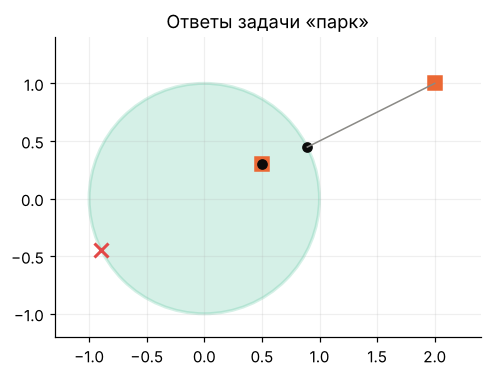

In [2]:
def kkt_report(a, x, mu):
    a, x = np.asarray(a, float), np.asarray(x, float)
    stat = x - a + 2 * mu * x                       # стационарность: grad f - mu grad h = x - a + 2 mu x
    h = 1 - x @ x                                   # допустимость: h >= 0
    print(f"a = {a}: x = {x.round(3)}, mu = {mu:.3f} | |стационарность| = {np.abs(stat).max():.1e}, "
          f"h = {h:.3f}, mu*h = {mu * h:.1e}")

for a in (HOUSE_IN, HOUSE_OUT):
    x, mu = park_solution(a)                        # ответ и множитель по формулам §2.1
    kkt_report(a, x, mu)
print("в конспекте: дом внутри — x* = a, mu = 0, h = 0.66; дом снаружи — x* = (0.894, 0.447), mu = 0.618")

x_far = -HOUSE_OUT / np.linalg.norm(HOUSE_OUT)      # второе решение системы на границе — самая дальняя точка
mu_far = -(np.linalg.norm(HOUSE_OUT) + 1) / 2
kkt_report(HOUSE_OUT, x_far, mu_far)
print("в конспекте: самая дальняя точка (-0.894, -0.447), mu = -1.618 < 0 — не минимум")

fig, ax = plt.subplots(figsize=(5, 4))
draw_park(ax)
for a in (HOUSE_IN, HOUSE_OUT):
    x, _ = park_solution(a)
    ax.plot(*a, "s", color=ORANGE, ms=9)            # дом
    ax.plot(*x, "o", color=INK, ms=6)               # ближайшая точка парка
    ax.plot([a[0], x[0]], [a[1], x[1]], color=GRAY, lw=1)
ax.plot(*x_far, "x", color=RED, ms=9, mew=2)        # самая дальняя точка границы
ax.set(xlim=(-1.3, 2.4), ylim=(-1.2, 1.4), title="Ответы задачи «парк»")
plt.show()

**Что видим.** У обоих ответов все четыре условия выполнены: стационарность — до машинной точности, $h\ge0$, $\mu\ge0$, $\mu h=0$. Внутри нулю равен $\mu$, снаружи — $h$. Дальняя точка удовлетворяет стационарности и $\mu h=0$, но $\mu=-1.618<0$: условие знака отсекает её.

### Демо (b). Активное множество: портфель руками

**Что проверяем.** Схема «угадай и проверь» из §3.1 находит ответ за две догадки. IPOPT даёт те же доли и те же множители со знаком минус.

**Что делает ячейка.** `portfolio_active(rho, A)` решает систему лекции 8, где доли из `A` равны нулю. Ячейка делает две догадки при $\rho=12\,\%$: $\mathcal A=\varnothing$ и $\mathcal A=\{1\}$. После каждой проверяет $x\ge0$ и $\mu\ge0$. Номера активов в коде — с нуля, поэтому $\{1\}$ в конспекте — это `[0]` в коде.

A = []: x = [-0.2015  0.4981  0.4324  0.271 ], lam_rho = 0.3511, mu = []
   x >= 0: False,  mu >= 0: True
A = [1]: x = [0.     0.1414 0.5026 0.356 ], lam_rho = 0.4731, mu = [0.0082]
   x >= 0: True,  mu >= 0: True
в конспекте: догадка 1 — x1 = -0.2015 < 0; догадка 2 — x = (0, 0.1414, 0.5026, 0.3560), mu1 = 0.0082


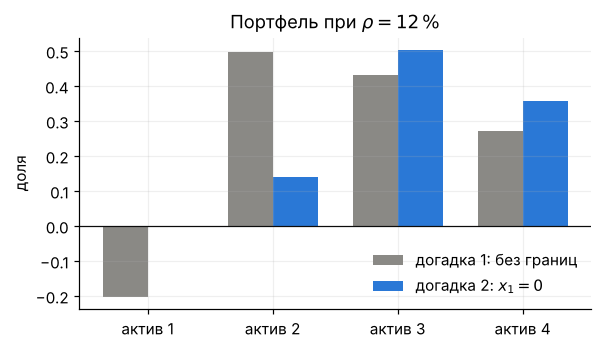

In [3]:
rho = 0.12
for A in ([], [0]):                                  # догадки: пусто, потом первая доля равна нулю
    x, lam1, lam_rho, mu = portfolio_active(rho, A)
    print(f"A = {[i + 1 for i in A]}: x = {x.round(4)}, lam_rho = {lam_rho:.4f}, mu = {mu.round(4)}")
    print(f"   x >= 0: {bool(x.min() >= -1e-12)},  mu >= 0: {bool(mu.size == 0 or mu.min() >= 0)}")
print("в конспекте: догадка 1 — x1 = -0.2015 < 0; догадка 2 — x = (0, 0.1414, 0.5026, 0.3560), mu1 = 0.0082")

x0 = portfolio_active(rho, [])[0]
x1 = portfolio_active(rho, [0])[0]
fig, ax = plt.subplots(figsize=(6, 3.2))
pos = np.arange(4)
ax.bar(pos - 0.18, x0, width=0.36, color=GRAY, label="догадка 1: без границ")
ax.bar(pos + 0.18, x1, width=0.36, color=BLUE, label="догадка 2: $x_1=0$")
ax.axhline(0, color=INK, lw=0.8)
ax.set(xticks=pos, xticklabels=[f"актив {i + 1}" for i in pos], ylabel="доля", title="Портфель при $\\rho=12\\,\\%$")
ax.legend()
plt.show()

**Что видим.** Первая догадка даёт $x_1=-0.20$ — проверка $x\ge0$ не проходит. Вторая догадка проходит обе проверки: доли неотрицательны, $\mu_1=0.0082\ge0$. Цена доходности $\lambda_\rho$ выросла с $0.351$ до $0.473$.

**Что делает ячейка.** Решает ту же задачу IPOPT через CasADi. Равенства идут в `g` с границами `lbg=ubg=0`, неравенства $x\ge0$ — в границы переменных `lbx=0`, `ubx=inf`. Множители равенств IPOPT возвращает в `lam_g`, множители границ — в `lam_x`.

In [4]:
xs = ca.SX.sym("x", 4)                                         # доли
nlp = {"x": xs,
       "f": 0.5 * ca.mtimes([xs.T, ca.DM(PF_SIGMA), xs]),       # риск
       "g": ca.vertcat(ca.sum1(xs) - 1,                         # весь капитал вложен
                       ca.dot(ca.DM(PF_R), xs) - rho)}          # доходность rho
solver = ca.nlpsol("pf", "ipopt", nlp, {"ipopt.print_level": 0, "print_time": 0, "ipopt.sb": "yes"})
res = solver(x0=np.ones(4) / 4, lbx=0, ubx=ca.inf, lbg=0, ubg=0)
x_ip = np.array(res["x"]).ravel()
print("IPOPT: итераций", solver.stats()["iter_count"], "| x =", x_ip.round(4))
print("lam_g =", np.array(res["lam_g"]).ravel().round(4), "| наши -lambda =", -np.round([-0.0265, 0.4731], 4))
print("lam_x =", np.array(res["lam_x"]).ravel().round(4), "| наши -mu =", -np.round([0.0082, 0, 0, 0], 4))
print("в конспекте: 9 итераций, lam_x = (-0.0082, 0, 0, 0), lam_g = (0.0265, -0.4731)")

IPOPT: итераций 9 | x = [0.     0.1414 0.5026 0.356 ]
lam_g = [ 0.0265 -0.4731] | наши -lambda = [ 0.0265 -0.4731]
lam_x = [-0.0082 -0.     -0.     -0.    ] | наши -mu = [-0.0082 -0.     -0.     -0.    ]
в конспекте: 9 итераций, lam_x = (-0.0082, 0, 0, 0), lam_g = (0.0265, -0.4731)


**Что видим.** IPOPT приходит к тем же долям за 9 итераций. Его множители — наши со знаком минус: и у равенств, как в лекции 8, и у границ. Отрицательный `lam_x` значит активную нижнюю границу.

### Демо (c). Уголок и гипербола: точки при $\mu h=\tau$

**Что проверяем.** Заменим $\mu h=0$ на $\mu h=\tau$ и возьмём ветвь с $\mu>0$, $h>0$. Точка задачи «парк» тогда лежит внутри парка. При уменьшении $\tau$ она приближается к ответу.

**Что делает ячейка.** Для дома $(2,\ 1)$ и $\tau=1,\ 0.1,\ 0.01,\ 0.001$ решает систему $x-a+2\mu x=0$, $\mu h=\tau$ функцией `park_tau`. Корень по $\mu$ она ищет там, где $\mu>0$ и $h>0$, — это и есть выбор ветви. Печатает $\mu$, $h$ и расстояние до ответа, рисует расстояние от $\tau$.

tau = 1.0   : x = (0.5068, 0.2534), mu = 1.4730, h = 0.6789, до ответа 0.4333
tau = 0.1   : x = (0.8287, 0.4144), mu = 0.7067, h = 0.1415, до ответа 0.0735
tau = 0.01  : x = (0.8873, 0.4436), mu = 0.6271, h = 0.0159, до ответа 0.0080
tau = 0.001 : x = (0.8937, 0.4469), mu = 0.6189, h = 0.0016, до ответа 0.0008
в конспекте: при tau = 0.1 расстояние 0.07, при tau = 0.01 — 0.008; mu -> 0.618


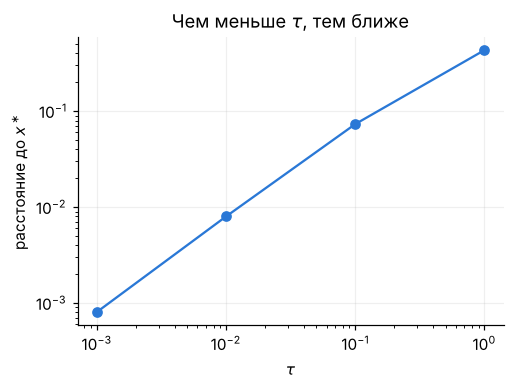

In [5]:
taus = [1.0, 0.1, 0.01, 0.001]
dist = []
x_star, mu_star = park_solution(HOUSE_OUT)
for tau in taus:
    x, mu = park_tau(HOUSE_OUT, tau)                # точка, где mu*h = tau
    h = 1 - x @ x
    dist.append(np.linalg.norm(x - x_star))
    print(f"tau = {tau:<6}: x = ({x[0]:.4f}, {x[1]:.4f}), mu = {mu:.4f}, h = {h:.4f}, до ответа {dist[-1]:.4f}")
print("в конспекте: при tau = 0.1 расстояние 0.07, при tau = 0.01 — 0.008; mu -> 0.618")

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.loglog(taus, dist, "o-", color=BLUE)
ax.set(xlabel="$\\tau$", ylabel="расстояние до $x^\\ast$", title="Чем меньше $\\tau$, тем ближе")
plt.show()

**Что видим.** Все точки внутри парка: $h>0$. Расстояние до ответа уменьшается примерно в 10 раз при каждом уменьшении $\tau$ в 10 раз, а $\mu$ стремится к $0.618$. Каждая точка — решение системы из одних уравнений, её находит метод Ньютона. Это идея метода внутренней точки (лекция 12).